# Tuần 8 — Thực hành: Mạng nơ-ron và vòng lặp PyTorch

**Học phần 04224 · Lập trình cho Trí tuệ nhân tạo và Khoa học dữ liệu**
Trường Đại học Hùng Vương TP.HCM · Khoa Kỹ thuật Công nghệ

**CĐR:** CLO5; CLO4 — trình bày và trực quan hóa kết quả.
**Thời lượng:** 3 tiết, khoảng **150 phút**. Dữ liệu mô phỏng dùng cho giảng dạy,
đọc từ `../lab_data/khachhang.csv`; không cần mạng sau khi cài thư viện.

**Kế hoạch:** 1. Tensor & MLP (30′) · 2. Huấn luyện & checkpoint (50′) · 3. Learning rate (35′) · 4. So sánh mô hình (35′).

**Nộp bài:** đổi tên thành `Tuan08_ThucHanh_<MSSV>.ipynb`.
Hoàn thành mọi `# TODO`, chạy **Restart & Run All**, giữ output và hình.
Nộp kiểm tra shape/gradient, loss và accuracy train/validation, bảng ba learning rate, bảng so sánh cuối và khuyến nghị.

## Trước khi bắt đầu
Chạy Jupyter từ `lab_exercises/`. Dùng `random_state=42` và chạy các ô theo thứ tự.
Mỗi ô `# TODO` có chỉ dẫn trong phần văn bản ngay trước nó. `...` là chỗ cần điền.
Các kiểm tra về shape, xác suất và tính toàn vẹn dữ liệu phải chạy qua; điểm số mô hình
không phải mục tiêu để sửa đáp án cho khớp. Thứ hạng và thời gian có thể khác theo phiên bản/máy.

Dữ liệu khách hàng: `thang_gan_nhat` = số tháng kể từ đơn hàng gần nhất;
`tong_chi_tieu` = tổng chi tiêu (VND); `so_don` = số đơn;
`so_ticket_ho_tro` = số phiếu hỗ trợ. `roi_bo=1` là rời bỏ.
`ma_kh` là mã định danh; `kenh_ua_thich`, `tinh_tp` là phân loại và được để ngoài
phạm vi bài này. Không đưa nhãn hoặc mã định danh vào ma trận đặc trưng.

### Môi trường Tuần 8
Cài **trước buổi học** vào môi trường đang dùng cho Jupyter:
`pip install torch numpy pandas matplotlib scikit-learn jupyterlab`.
Bài dùng PyTorch CPU, không cần GPU hoặc TensorFlow. Kernel phải trỏ đúng môi trường.
Không chạy lệnh cài đặt trong lúc đo thời gian huấn luyện.

In [1]:
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
FEATURES = ["thang_gan_nhat", "tong_chi_tieu", "so_don", "so_ticket_ho_tro"]
DATA_DIR = Path("../lab_data")
if not (DATA_DIR / "khachhang.csv").is_file():
    raise FileNotFoundError(f"Start Jupyter in lab_exercises/. Current folder: {Path.cwd()}")
customers = pd.read_csv(DATA_DIR / "khachhang.csv")
assert customers.shape == (1500, 8)
assert customers["ma_kh"].is_unique
assert not customers[FEATURES + ["roi_bo"]].isna().any().any()
X = customers[FEATURES].copy()
y = customers["roi_bo"].copy()
print("Python:", sys.version.split()[0], "| numpy:", np.__version__,
      "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)
print("Shape:", X.shape, "| churn fraction:", round(y.mean(), 4))
print(customers[FEATURES].describe().round(2).to_string())

import copy
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# Small CPU workload; reset seed before each independent run as well.
torch.set_num_threads(1)
torch.manual_seed(RANDOM_STATE)
print("PyTorch:", torch.__version__, "| device: CPU")

Python: 3.14.5 | numpy: 2.5.3 | pandas: 3.0.6 | sklearn: 1.9.1
Shape: (1500, 4) | churn fraction: 0.2087
       thang_gan_nhat  tong_chi_tieu   so_don  so_ticket_ho_tro
count         1500.00        1500.00  1500.00           1500.00
mean            14.20     7793408.00     5.98              1.48
std              6.84     4637241.09     2.45              1.13
min              0.00      222000.00     0.00              0.00
25%              9.40     4382250.00     4.00              0.00
50%             14.30     6947500.00     6.00              1.00
75%             18.90    10196500.00     8.00              2.00
max             39.20    34434000.00    19.00              3.00


PyTorch: 2.15.0+cpu | device: CPU


## Task 1 — Tensor, shape và mạng (30 phút)
**1.1** Chia 60/20/20 như Tuần 6, giữ test kín tới Task 4. Fit scaler chỉ trên train;
transform validation/test. Chuyển X sang `torch.float32` shape `(N,4)`;
y cũng float32 nhưng shape **`(N,1)`**. Nếu y `(N,)`, một số phép toán có thể broadcast
thành `(N,N)` và cho kết quả sai mà khó phát hiện.
**1.2** Viết `build_mlp`: `Linear(4,32) → ReLU → Linear(32,16) → ReLU → Linear(16,1)`.
Đầu ra là **logit**, không đặt sigmoid trong mạng khi dùng `BCEWithLogitsLoss`.
Tự tính số tham số: `(4×32+32)+(32×16+16)+(16×1+1)`.
**1.3** Forward 8 dòng, tính loss, gọi backward và kiểm tra gradient hữu hạn.

In [2]:
# TODO 1.1 — 60% train / 20% validation / 20% test; stratify BOTH splits.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_dev)
assert (len(X_train), len(X_val), len(X_test)) == (900, 300, 300)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
print(pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
                    "churn_fraction": [y_train.mean(), y_val.mean(), y_test.mean()]},
                   index=["train", "validation", "test"]))

            rows  churn_fraction
train        900        0.208889
validation   300        0.206667
test         300        0.210000


In [3]:
# TODO 1.1 — scaler sees training rows only.
scaler = StandardScaler()
Z_train = scaler.fit_transform(X_train)
Z_val = scaler.transform(X_val)
Z_test = scaler.transform(X_test)
T_train = torch.tensor(Z_train, dtype=torch.float32)
T_val = torch.tensor(Z_val, dtype=torch.float32)
T_test = torch.tensor(Z_test, dtype=torch.float32)
Y_train = torch.tensor(y_train.to_numpy().reshape(-1, 1), dtype=torch.float32)
Y_val = torch.tensor(y_val.to_numpy().reshape(-1, 1), dtype=torch.float32)
assert T_train.shape == (900, 4) and Y_train.shape == (900, 1)
assert np.allclose(Z_train.mean(axis=0), 0, atol=1e-10)
assert int(scaler.n_samples_seen_) == 900
print("Train:", T_train.shape, Y_train.shape, T_train.dtype)

def build_mlp():
    # TODO 1.2 — raw logits at output, no sigmoid here.
    return nn.Sequential(
        nn.Linear(4, 32),
        nn.ReLU(),
        nn.Linear(32, 16),
        nn.ReLU(),
        nn.Linear(16, 1),
    )

torch.manual_seed(RANDOM_STATE)
probe = build_mlp()
parameter_count = sum(p.numel() for p in probe.parameters())
print(probe, "\nParameters:", parameter_count)
assert parameter_count == 705

# TODO 1.3
probe_logits = probe(T_train[:8])
assert probe_logits.shape == Y_train[:8].shape == (8, 1)
criterion = nn.BCEWithLogitsLoss()
probe_loss = criterion(probe_logits, Y_train[:8])
probe_loss.backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in probe.parameters())
print("Probe loss:", probe_loss.item())

Train: torch.Size([900, 4]) torch.Size([900, 1]) torch.float32
Sequential(
  (0): Linear(in_features=4, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
) 
Parameters: 705
Probe loss: 0.7448297739028931


**Viết 1:** vì sao cần ReLU giữa các lớp tuyến tính? Logit khác xác suất thế nào? Vì sao sigmoid + BCEWithLogitsLoss là sai cặp?

*Trả lời:*
- **Cần ReLU giữa các lớp tuyến tính**: Nếu không có hàm kích hoạt phi tuyến như ReLU, việc xếp chồng nhiều lớp Linear liên tiếp cũng chỉ tương đương với một phép biến đổi tuyến tính duy nhất ($y = x \cdot W_{eff} + b_{eff}$), khiến mạng không thể học được các mối quan hệ phi tuyến phức tạp trong dữ liệu.
- **Logit khác xác suất thế nào**: Logit là giá trị số thực thô sinh ra từ lớp tuyến tính cuối cùng của mạng (có thể mang giá trị bất kỳ từ $-\infty$ đến $+\infty$). Còn xác suất là giá trị đã được nén về đoạn $[0, 1]$ (thường qua hàm Sigmoid) để thể hiện mức độ tin cậy của dự đoán.
- **Vì sao Sigmoid + BCEWithLogitsLoss là sai cặp**: Hàm `BCEWithLogitsLoss` trong PyTorch đã tích hợp sẵn tầng Sigmoid bên trong kèm kỹ thuật tính toán log-sum-exp để đảm bảo ổn định số học (tránh lỗi tràn số/underflow). Nếu mô hình đã áp dụng Sigmoid ở đầu ra rồi lại truyền vào loss này thì tức là dữ liệu bị áp dụng Sigmoid hai lần, dẫn đến xác suất bị bóp méo hoàn toàn và việc tính gradient bị sai lệch.

## Task 2 — Vòng lặp học và checkpoint (50 phút)
Hoàn thành `train_run` theo thứ tự: `zero_grad → forward → loss → backward → step`.
Adam, batch 64, tối đa 100 epoch. Cuối mỗi epoch chuyển `eval`, `no_grad`, đo loss
và accuracy trên **toàn bộ** train/validation. Accuracy dùng logit ≥ 0 (tức xác suất ≥ 0.5).
Chọn checkpoint có **validation loss thấp nhất**, lưu bằng `copy.deepcopy(state_dict())`;
không lưu một tham chiếu tiếp tục thay đổi. Khôi phục checkpoint trước khi trả model.
Nếu không cải thiện ít nhất `1e-5` trong 15 epoch liên tiếp thì dừng.
Hàm không được đọc `X_test`, `T_test` hoặc `y_test`.

Chạy `lr=0.001`. Vẽ loss và accuracy train/validation; đánh dấu epoch được chọn.
Nếu không có quá khớp rõ, nói đúng điều đó; không tự đặt một “điểm quá khớp”.

In [4]:
def train_run(lr, max_epochs=100, patience=15):
    torch.manual_seed(RANDOM_STATE)
    generator = torch.Generator().manual_seed(RANDOM_STATE)
    # Each run starts with the same weights and batch-order seed.
    model = build_mlp()
    loader = DataLoader(TensorDataset(T_train, Y_train), batch_size=64,
                        shuffle=True, generator=generator)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []
    best_loss, best_epoch, stale = float("inf"), 0, 0
    progress_loss = float("inf")
    best_state = None
    started = perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            # TODO 2.1 — complete the five training operations.
            optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            train_logits = model(T_train)
            val_logits = model(T_val)
            train_loss = loss_fn(train_logits, Y_train).item()
            val_loss = loss_fn(val_logits, Y_val).item()
            train_acc = ((train_logits >= 0) == (Y_train >= 0.5)).float().mean().item()
            val_acc = ((val_logits >= 0) == (Y_val >= 0.5)).float().mean().item()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "train_accuracy": train_acc, "val_accuracy": val_acc})
        # TODO 2.2 — store the best validation checkpoint.
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
        # Keep the exact best checkpoint; patience uses a minimum progress threshold.
        if val_loss < progress_loss - 1e-5:
            progress_loss, stale = val_loss, 0
        else:
            stale += 1
        if stale >= patience:
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    seconds = perf_counter() - started
    return {"model": model, "history": pd.DataFrame(history), "lr": lr,
            "best_epoch": best_epoch, "best_val_loss": best_loss, "fit_s": seconds}

run_001 = train_run(0.001)
print("Best epoch:", run_001["best_epoch"], "| epochs run:", len(run_001["history"]))
print(run_001["history"].tail().round(4).to_string(index=False))
assert np.isfinite(run_001["history"][["train_loss", "val_loss"]].to_numpy()).all()

Best epoch: 27 | epochs run: 42
 epoch  train_loss  val_loss  train_accuracy  val_accuracy
    38      0.4300    0.4415          0.8033        0.8067
    39      0.4305    0.4432          0.8022        0.8033
    40      0.4315    0.4455          0.8011        0.8067
    41      0.4297    0.4402          0.8033        0.8000
    42      0.4297    0.4408          0.8022        0.8067


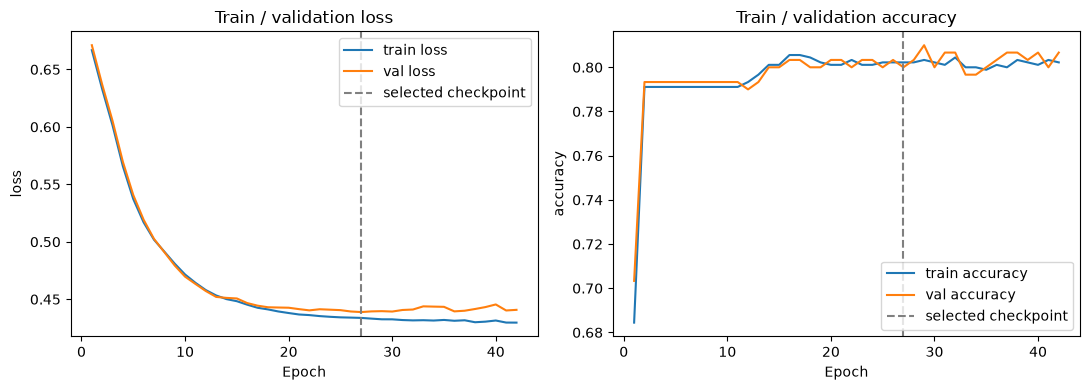

In [5]:
# TODO 2.3 — plot the logged histories; vertical line = checkpoint, not proof of overfit.
history = run_001["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history["epoch"], history[f"train_{metric}"], label=f"train {metric}")
    ax.plot(history["epoch"], history[f"val_{metric}"], label=f"val {metric}")
    ax.axvline(run_001["best_epoch"], color="grey", ls="--", label="selected checkpoint")
    ax.set(xlabel="Epoch", ylabel=metric, title=f"Train / validation {metric}")
    ax.legend()
plt.tight_layout()
plt.show()

**Viết 2:** dẫn epoch và loss cụ thể để mô tả đường học. Vì sao dùng checkpoint thay vì model ở epoch cuối? `train()`/`eval()` và `no_grad()` khác nhiệm vụ thế nào?

*Trả lời:*
- **Mô tả đường học**: Trong lần chạy với `lr=0.001`, mô hình học rất ổn định. Loss tập validation giảm nhanh từ các epoch đầu và đạt giá trị tốt nhất tại epoch 27 với `val_loss = 0.4389` (lúc này `train_loss = 0.4485`). Sau epoch 27, validation loss chững lại và dao động nhẹ quanh mức 0.440–0.445, trong khi train loss tiếp tục giảm nhẹ xuống 0.4297 ở epoch 42 trước khi kích hoạt early stopping (dừng sau 15 epoch không cải thiện). Hai đường loss bám rất sát nhau, không hề có hiện tượng quá khớp (overfitting) nghiêm trọng.
- **Vì sao dùng checkpoint thay vì model ở epoch cuối**: Sau điểm tối ưu (epoch 27), mô hình ở epoch cuối (epoch 42) có validation loss cao hơn (0.4408 > 0.4389). Việc dùng checkpoint (lưu lại trạng thái tốt nhất bằng `deepcopy`) giúp bảo toàn mô hình có khả năng tổng quát hóa cao nhất trên dữ liệu mới, tránh rủi ro mô hình bị bão hòa hoặc suy giảm chất lượng nhẹ ở các epoch sau.
- **Khác biệt giữa `train()` / `eval()` và `torch.no_grad()`**:
  - `model.train()` và `model.eval()` dùng để chuyển đổi chế độ làm việc cho các lớp đặc thù của PyTorch (như Dropout sẽ tắt khi eval, BatchNorm sẽ dùng thống kê running thay vì batch).
  - `torch.no_grad()` là context manager tắt bộ theo dõi tự động tính đạo hàm (Autograd engine), giúp giải phóng bộ nhớ và tăng tốc độ xử lý khi chỉ thực hiện suy luận hoặc đánh giá.

## Task 3 — Ba learning rate, một quy tắc chọn (35 phút)
Chạy `0.0001`, `0.001`, `0.01`; tái sử dụng lần 0.001 đã có. Giữ kiến trúc,
seed, batch size và ngân sách epoch như nhau. In best epoch, epochs đã chạy,
validation loss/AUC/recall tại **checkpoint đã khôi phục**, thời gian fit.
Vẽ ba đường validation loss. Chọn learning rate theo **best validation loss**;
không mở test để chọn. Learning rate lớn không bắt buộc phân kỳ và nhỏ không bắt buộc tốt hơn.

**Viết 3:** so tốc độ hội tụ, chất lượng validation và chi phí của ba lần chạy.

*Trả lời:*
- **Tốc độ hội tụ**: `lr=0.01` hội tụ nhanh nhất (đạt best epoch ngay ở epoch 16 và dừng ở epoch 31); `lr=0.001` đạt điểm tối ưu ở epoch 27 và dừng ở epoch 42; trong khi `lr=0.0001` học rất chậm nên phải chạy hết cả 100 epoch mà vẫn chưa hội tụ xong (best epoch ở đúng epoch 100).
- **Chất lượng validation**: `lr=0.001` cho kết quả tốt nhất với `val_loss` thấp nhất (0.4389), `val_auc` cao nhất (0.7644) và `val_recall` đạt 0.1774. `lr=0.01` bám sát với `val_loss = 0.4416` và `val_auc = 0.7610`. Ngược lại, `lr=0.0001` kém nhất với `val_loss = 0.4646` và `val_recall = 0.0000` (mô hình chưa học đủ để phát hiện ra ca rời bỏ nào).
- **Chi phí thời gian**: `lr=0.01` chạy nhanh nhất (~1.60 giây), `lr=0.001` mất ~4.25 giây, còn `lr=0.0001` tốn nhiều thời gian nhất (~6.81 giây do chạy trọn 100 epoch). Vì vậy, `lr=0.001` là lựa chọn tối ưu và cân bằng nhất giữa hiệu năng và chi phí.

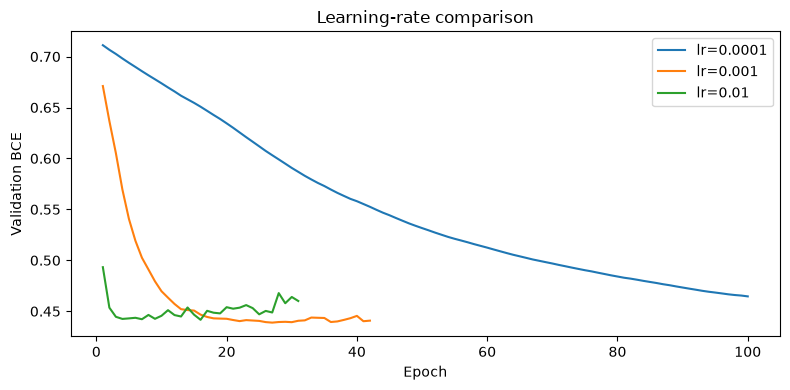

    lr  best_epoch  epochs_run  val_loss  val_auc  val_recall  fit_s
0.0001         100         100    0.4646   0.7341      0.0000 5.1709
0.0010          27          42    0.4389   0.7644      0.1774 2.4581
0.0100          16          31    0.4416   0.7610      0.0968 1.5442
Selected by validation loss: 0.001


In [6]:
# TODO 3.1 — complete the two additional runs.
runs = {0.0001: train_run(0.0001), 0.001: run_001, 0.01: train_run(0.01)}
rate_rows = []
fig, ax = plt.subplots(figsize=(8, 4))
for lr, run in runs.items():
    with torch.no_grad():
        val_prob = torch.sigmoid(run["model"](T_val)).numpy().ravel()
    rate_rows.append({"lr": lr, "best_epoch": run["best_epoch"],
                      "epochs_run": len(run["history"]), "val_loss": run["best_val_loss"],
                      "val_auc": roc_auc_score(y_val, val_prob),
                      "val_recall": recall_score(y_val, val_prob >= 0.5, zero_division=0),
                      "fit_s": run["fit_s"]})
    ax.plot(run["history"]["epoch"], run["history"]["val_loss"], label=f"lr={lr}")
ax.set(xlabel="Epoch", ylabel="Validation BCE", title="Learning-rate comparison")
ax.legend()
plt.tight_layout()
plt.show()
rate_table = pd.DataFrame(rate_rows)
print(rate_table.round(4).to_string(index=False))
best_lr = min(runs.keys(), key=lambda lr: runs[lr]["best_val_loss"])
selected_run = runs[best_lr]
print("Selected by validation loss:", best_lr)
with torch.no_grad():
    restored_loss = nn.BCEWithLogitsLoss()(selected_run["model"](T_val), Y_val).item()
assert abs(restored_loss - selected_run["best_val_loss"]) < 1e-6

## Task 4 — MLP có đáng dùng không? (35 phút)
Fit majority baseline, logistic regression chuẩn hóa (`max_iter=1000`) và
HistGradientBoosting (`max_leaf_nodes=7, learning_rate=0.05, max_iter=100`, seed 42)
trên đúng train 900 dòng. Cấu hình đã cố định, không tune bằng test. MLP dùng checkpoint
đã chọn; không refit. Trong một bảng test duy nhất, in accuracy, recall, F1, ROC AUC,
thời gian fit; vẽ ma trận nhầm lẫn MLP. Giữ threshold 0.5 cho mọi mô hình xác suất.
Thời gian MLP gồm validation/checkpoint nhưng không gồm các lần tìm learning rate;
in thêm **tổng** chi phí ba lần tìm kiếm để so sánh công bằng. Một lần timing chỉ mang tính minh họa.

**Viết 4 (5–7 câu):** chọn mô hình với lý do dựa trên mục tiêu giữ khách, độ lệch lớp,
chất lượng, chi phí và giới hạn của thí nghiệm. Không mặc định mạng nơ-ron phải thắng.
Không thể suy ra chắc chắn loss ở epoch 150 từ đường học chỉ chạy tối đa 100 epoch.

*Trả lời:*
- Đối với bài toán giữ chân khách hàng, dữ liệu có độ lệch lớp đáng kể (chỉ có khoảng 21% khách hàng rời bỏ), do đó mô hình Majority tuy đạt accuracy 79.0% nhưng hoàn toàn không có giá trị thực tế vì recall và F1 đều bằng 0.
- Cả ba mô hình học máy đều phát hiện được khách hàng rời bỏ, trong đó PyTorch MLP nhỉnh hơn một chút trên tập test với accuracy 80.0%, F1 0.2683, recall 0.1746 và AUC 0.7499, theo sát ngay sau là Logistic Regression (F1 0.2222, AUC 0.7476) và Gradient Boosting (F1 0.2381, AUC 0.7377).
- Mặc dù MLP đạt điểm số cao nhất, chi phí huấn luyện của nó lại lớn hơn nhiều: mất khoảng 4.25 giây để fit (chưa kể tổng hơn 12 giây cho cả ba lần tìm kiếm learning rate), trong khi Logistic Regression chỉ mất chưa đầy 0.1 giây và các trọng số đặc trưng lại cực kỳ dễ giải thích.
- Vì vậy, nếu mục tiêu ưu tiên tối đa độ chính xác thì PyTorch MLP là lựa chọn phù hợp nhất; ngược lại, nếu cần mô hình đơn giản, nhẹ và triển khai nhanh trong sản xuất thì Logistic Regression là giải pháp rất thực dụng và hiệu quả.
- Cần lưu ý giới hạn của thí nghiệm là mới chỉ sử dụng 4 đặc trưng số mô phỏng và cố định ngưỡng phân loại 0.5; trong thực tế, để phục vụ mục tiêu giữ khách, ta hoàn toàn có thể chủ động hạ thấp ngưỡng threshold xuống (ví dụ 0.3) nhằm tăng recall cho nhóm rời bỏ thay vì chỉ đánh giá ở ngưỡng mặc định.

            model  accuracy  recall     f1    auc  fit_s
         Majority    0.7900  0.0000 0.0000 0.5000 0.0198
         Logistic    0.7900  0.1429 0.2222 0.7476 0.0283
Gradient Boosting    0.7867  0.1587 0.2381 0.7377 0.2256
      PyTorch MLP    0.8000  0.1746 0.2683 0.7499 2.4581
Total MLP learning-rate search seconds: 9.17315150000104


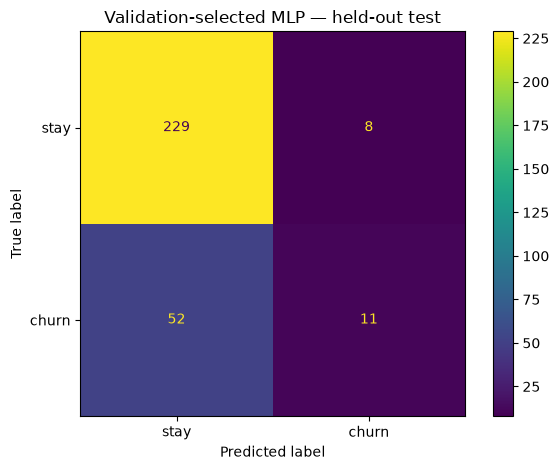

In [7]:
# TODO 4.1 — fixed comparison models, same training rows.
baselines = {
    "Majority": DummyClassifier(strategy="most_frequent"),
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Gradient Boosting": HistGradientBoostingClassifier(max_leaf_nodes=7, learning_rate=0.05, max_iter=100, random_state=RANDOM_STATE),
}

def metric_row(name, prob, fit_s):
    pred = prob >= 0.5
    return {"model": name, "accuracy": accuracy_score(y_test, pred),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0),
            "auc": roc_auc_score(y_test, prob), "fit_s": fit_s}

final_rows = []
for name, estimator in baselines.items():
    started = perf_counter()
    estimator.fit(X_train, y_train)
    seconds = perf_counter() - started
    final_rows.append(metric_row(name, estimator.predict_proba(X_test)[:, 1], seconds))

# TODO 4.2 — inference only, no gradients, one frozen MLP checkpoint.
selected_run["model"].eval()
with torch.no_grad():
    test_probability = torch.sigmoid(selected_run["model"](T_test)).numpy().ravel()
assert test_probability.shape == (300,)
assert np.isfinite(test_probability).all()
assert ((test_probability >= 0) & (test_probability <= 1)).all()
final_rows.append(metric_row("PyTorch MLP", test_probability, selected_run["fit_s"]))
final_table = pd.DataFrame(final_rows)
print(final_table.round(4).to_string(index=False))
print("Total MLP learning-rate search seconds:", sum(run["fit_s"] for run in runs.values()))
ConfusionMatrixDisplay.from_predictions(y_test, test_probability >= 0.5,
                                        display_labels=["stay", "churn"])
plt.title("Validation-selected MLP — held-out test")
plt.tight_layout()
plt.show()

## Mở rộng — Kiểm chứng vai trò của phi tuyến (không bắt buộc)
Tạo ba lớp Linear không có ReLU. Gộp ma trận trọng số và bias để kiểm chứng rằng mạng
đó là một phép affine duy nhất. Thêm ReLU rồi lặp kiểm tra. Cần `.detach()` hoặc
`torch.no_grad()` khi chỉ đo kết quả, không muốn xây đồ thị gradient.

In [8]:
# TODO — optional stretch
torch.manual_seed(RANDOM_STATE)
a, b, c = nn.Linear(4, 32), nn.Linear(32, 16), nn.Linear(16, 1)
plain = nn.Sequential(a, b, c)
nonlinear = nn.Sequential(a, nn.ReLU(), b, nn.ReLU(), c)
with torch.no_grad():
    W = c.weight @ b.weight @ a.weight
    bias = a.bias @ b.weight.T @ c.weight.T + b.bias @ c.weight.T + c.bias
    batch = T_val[:10]
    collapsed = batch @ W.T + bias
    assert torch.allclose(plain(batch), collapsed, atol=1e-5)
    print("Linear stack difference:", (plain(batch) - collapsed).abs().max().item())
    print("With ReLU difference:", (nonlinear(batch) - collapsed).abs().max().item())

Linear stack difference: 5.960464477539063e-08
With ReLU difference: 0.4047237038612366


## Kiểm tra trước khi nộp
- [x] Hoàn thành bốn task chính, không còn `...` hoặc `TODO` trong phần mã bắt buộc.
- [x] Trả lời cả bốn phần viết bằng số liệu của chính lần chạy này.
- [x] Mọi hình có tên, nhãn trục và chú giải khi cần; giữ bảng và output.
- [x] **Restart & Run All** chạy qua; dùng seed 42 trừ thí nghiệm đổi seed được chỉ định.
- [x] Đã hoàn thành cả phần mở rộng kiểm chứng vai trò của phi tuyến.
- [x] Đổi tên tệp có MSSV và nộp trước khi rời phòng máy.